# EDA: hoteles y pisos turísticos

## Los datos

Trabajamos con dos tablas que están en la carpeta datos.

En **hoteles.csv** están las reservas de dos hoteles de Portugal, uno de ciudad (Lisboa) y otro de playa (Algarve), entre julio de 2015 y agosto de 2017. Este lo usa el profe. Nos quedamos con estas columnas:

| Columna | Qué es |
|---|---|
| hotel | City Hotel (ciudad) o Resort Hotel (playa) |
| is_canceled | 1 si la reserva se canceló, 0 si no |
| lead_time | días entre que se hizo la reserva y el día de llegada |
| arrival_date_year, arrival_date_month | año y mes de llegada |
| stays_in_weekend_nights, stays_in_week_nights | noches de fin de semana y de entre semana |
| adults, children, babies | adultos, niños y bebés |
| meal | comida contratada: BB desayuno, HB media pensión, FB pensión completa, SC sin comida |
| country | país del cliente, con tres letras (PRT Portugal, ESP España...) |
| deposit_type | No Deposit (sin depósito), Non Refund (pagado y sin devolución), Refundable (se devuelve) |
| agent, company | número de la agencia o de la empresa que hizo la reserva |
| adr | precio medio por noche, en euros |

En **airbnb_madrid.csv** están los pisos turísticos de Madrid que había anunciados en Airbnb el 17 de septiembre de 2026. Este es el vuestro, y de él nos quedamos con estas:

| Columna | Qué es |
|---|---|
| id | número del anuncio |
| neighbourhood_group, neighbourhood | distrito y barrio |
| latitude, longitude | dónde está el piso |
| room_type | Entire home/apt (piso entero), Private room (habitación), Shared room (habitación compartida), Hotel room |
| price | precio por noche, en euros |
| minimum_nights | noches mínimas que hay que reservar |
| number_of_reviews, reviews_per_month | reseñas en total y reseñas al mes |
| calculated_host_listings_count | cuántos pisos tiene en Madrid el anfitrión de ese piso |
| availability_365 | días libres en el próximo año |
| license | número de licencia turística, si lo tiene |

## 0. Comprobación

In [56]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. Primer vistazo

Antes de calcular nada, miramos cuántas filas y columnas hay y de qué tipo es cada columna.

In [57]:
hoteles = pd.read_csv("hoteles.csv")
hoteles.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [58]:
print(hoteles.shape) # filas y columnas

(119390, 32)


In [59]:
hoteles.info() # cuantas filas y columnas, tipos de datos, memoria usada

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [60]:
hoteles = hoteles[["hotel", "is_canceled", "lead_time", "arrival_date_year", "arrival_date_month",
                   "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                   "meal", "country", "deposit_type", "agent", "company", "adr"]]
hoteles.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,deposit_type,agent,company,adr
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,NaN,NaN,0.0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,NaN,NaN,0.0
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,BB,GBR,No Deposit,NaN,NaN,75.0
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,BB,GBR,No Deposit,304.0,NaN,75.0
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,BB,GBR,No Deposit,240.0,NaN,98.0


In [61]:
hoteles.columns = ["hotel", "cancelada", "antelacion", "año", "mes", "noches_finde", "noches_semana", "adultos", "ninos", "bebes",
                   "comida", "pais", "deposito", "agente", "empresa", "precio_noche"]

hoteles.head()

,hotel,cancelada,antelacion,año,mes,noches_finde,noches_semana,adultos,ninos,bebes,comida,pais,deposito,agente,empresa,precio_noche
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,NaN,NaN,0.0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,NaN,NaN,0.0
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,BB,GBR,No Deposit,NaN,NaN,75.0
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,BB,GBR,No Deposit,304.0,NaN,75.0
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,BB,GBR,No Deposit,240.0,NaN,98.0


### Ejercicios

**1.1** Carga datos/airbnb_madrid.csv en una tabla que se llame pisos y enseña las primeras filas.

In [62]:
pisos = pd.read_csv("airbnb_madrid.csv")
pisos.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,23203785,"Apartamentos de Simone, Apartamento Picasso",16177101,1462596901119084538,Simone,Centro,Sol,40.419064,-3.704552,Entire home/apt,365.0,4.0,50,2025-04-28,0.38,5,0,0,NaN
1,23205290,Hermosilla III by Home at Homes,9228673,1462568646073234369,Home At Homes,Salamanca,Recoletos,40.425290,-3.683830,Entire home/apt,387.0,7.0,47,2025-11-18,0.45,4,83,2,Spain - National registration number<br />ESFC...
2,23216406,"Luminoso apartamento centro de Madrid, Atocha",61810218,1466760326474610119,Isabel,Centro,Embajadores,40.406210,-3.702160,Entire home/apt,NaN,2.0,30,2019-12-08,0.29,1,0,0,NaN
3,23226721,Céntrico y Cómodo Estudio en Atocha-Retiro WIFI,172793556,1468677043271793162,Máximo,Centro,Embajadores,40.406330,-3.698371,Entire home/apt,67.0,28.0,47,2026-06-20,0.45,1,131,3,Spain - National registration number<br />ESFC...
4,23243363,Luxury 100 sqm roof terrace apt. Best location.,229284,1462513244142164812,Luis,Chamberí,Arapiles,40.430090,-3.705720,Entire home/apt,350.0,7.0,3,2025-04-19,0.06,1,41,0,NaN


**1.2** ¿Cuántas filas y columnas tiene?

Resultado esperado: (23109, 19)

In [63]:
print(pisos.shape) # filas y columnas

(23109, 19)


**1.3** Usa info(). ¿Qué columnas son de texto? ¿Cuáles tienen menos valores que filas?

In [64]:
pisos.info()

<class 'pandas.DataFrame'>
RangeIndex: 23109 entries, 0 to 23108
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              23109 non-null  int64  
 1   name                            23109 non-null  str    
 2   host_id                         23109 non-null  int64  
 3   host_profile_id                 23109 non-null  int64  
 4   host_name                       23109 non-null  str    
 5   neighbourhood_group             23109 non-null  str    
 6   neighbourhood                   23109 non-null  str    
 7   latitude                        23109 non-null  float64
 8   longitude                       23109 non-null  float64
 9   room_type                       23109 non-null  str    
 10  price                           18785 non-null  float64
 11  minimum_nights                  21380 non-null  float64
 12  number_of_reviews               23109 non-n

**1.4** Quédate solo con estas columnas: id, neighbourhood_group, neighbourhood, latitude, longitude, room_type, price, minimum_nights, number_of_reviews, reviews_per_month, calculated_host_listings_count, availability_365 y license. Así quitamos los nombres de los anfitriones, que no necesitamos.

In [65]:
pisos = pisos[["id", "neighbourhood_group", "neighbourhood", "latitude", "longitude", "room_type", "price",
               "minimum_nights", "number_of_reviews", "reviews_per_month", "calculated_host_listings_count",
               "availability_365", "license"]]
pisos.head()

,id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,license
0,23203785,Centro,Sol,40.419064,-3.704552,Entire home/apt,365.0,4.0,50,0.38,5,0,NaN
1,23205290,Salamanca,Recoletos,40.425290,-3.683830,Entire home/apt,387.0,7.0,47,0.45,4,83,Spain - National registration number<br />ESFC...
2,23216406,Centro,Embajadores,40.406210,-3.702160,Entire home/apt,NaN,2.0,30,0.29,1,0,NaN
3,23226721,Centro,Embajadores,40.406330,-3.698371,Entire home/apt,67.0,28.0,47,0.45,1,131,Spain - National registration number<br />ESFC...
4,23243363,Chamberí,Arapiles,40.430090,-3.705720,Entire home/apt,350.0,7.0,3,0.06,1,41,NaN


**1.5** Ponles estos nombres, en el mismo orden: id, distrito, barrio, latitud, longitud, tipo, precio, noches_minimas, reseñas, reseñas_mes, pisos_anfitrion, dias_libres y licencia.

In [66]:
pisos.columns = ["id", "distrito", "barrio", "latitud", "longitud", "tipo", "precio",
                 "noches_minimas", "reseñas", "reseñas_mes", "pisos_anfitrion",
                 "dias_libres", "licencia"]
pisos.head()

,id,distrito,barrio,latitud,longitud,tipo,precio,noches_minimas,reseñas,reseñas_mes,pisos_anfitrion,dias_libres,licencia
0,23203785,Centro,Sol,40.419064,-3.704552,Entire home/apt,365.0,4.0,50,0.38,5,0,NaN
1,23205290,Salamanca,Recoletos,40.425290,-3.683830,Entire home/apt,387.0,7.0,47,0.45,4,83,Spain - National registration number<br />ESFC...
2,23216406,Centro,Embajadores,40.406210,-3.702160,Entire home/apt,NaN,2.0,30,0.29,1,0,NaN
3,23226721,Centro,Embajadores,40.406330,-3.698371,Entire home/apt,67.0,28.0,47,0.45,1,131,Spain - National registration number<br />ESFC...
4,23243363,Chamberí,Arapiles,40.430090,-3.705720,Entire home/apt,350.0,7.0,3,0.06,1,41,NaN


In [67]:
hoteles["comida"] = hoteles["comida"].replace("Undefined", "SC")   # Undefined es lo mismo que SC, sin comida
hoteles["comida"].value_counts()

comida
BB    92310
HB    14463
SC    11819
FB      798
Name: count, dtype: int64

## 2. Los huecos

Contamos lo que falta en cada columna. Con cada una decidimos si la quitamos entera, si quitamos esas filas o si rellenamos los huecos.

In [68]:
hoteles.isna().sum() # isna() devuelve un dataframe con True/False según si el valor es NaN o no. sum() suma los valores True (1) y False (0) por columna, devolviendo el número de valores NaN por columna.

hotel                 0
cancelada             0
antelacion            0
año                   0
mes                   0
noches_finde          0
noches_semana         0
adultos               0
ninos                 4
bebes                 0
comida                0
pais                488
deposito              0
agente            16340
empresa          112593
precio_noche          0
dtype: int64

In [69]:
porcentaje = hoteles.isna().sum() / len(hoteles) * 100
porcentaje.round(1)

hotel             0.0
cancelada         0.0
antelacion        0.0
año               0.0
mes               0.0
noches_finde      0.0
noches_semana     0.0
adultos           0.0
ninos             0.0
bebes             0.0
comida            0.0
pais              0.4
deposito          0.0
agente           13.7
empresa          94.3
precio_noche      0.0
dtype: float64

In [70]:
hoteles = hoteles.drop(columns=["empresa"]) # eliminamos la columna empresa porque tiene demasiados valores NaN
print(hoteles.shape) # filas y columnas

(119390, 15)


In [71]:
hoteles = hoteles.dropna(subset=["pais", "ninos"]) # eliminamos las filas que tienen NaN en la columna pais
print(hoteles.shape) # filas y columnas

(118898, 15)


In [72]:
hoteles["agente"] = hoteles["agente"].fillna(0) # rellenamos los valores NaN de la columna agente con 0
hoteles.isna().sum() # comprobamos que ya no hay valores NaN en la columna agente

hotel            0
cancelada        0
antelacion       0
año              0
mes              0
noches_finde     0
noches_semana    0
adultos          0
ninos            0
bebes            0
comida           0
pais             0
deposito         0
agente           0
precio_noche     0
dtype: int64

### Ejercicios

**2.1** Cuenta los huecos de cada columna de pisos.

In [73]:
pisos.isna().sum() # isna() devuelve un dataframe con True/False según si el valor es NaN o no. sum() suma los valores True (1) y False (0) por columna, devolviendo el número de valores NaN por columna.

id                     0
distrito               0
barrio                 0
latitud                0
longitud               0
tipo                   0
precio              4324
noches_minimas      1729
reseñas                0
reseñas_mes         3815
pisos_anfitrion        0
dias_libres            0
licencia           10913
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

Resultado esperado: precio 18.7, noches_minimas 7.5, reseñas_mes 16.5 y licencia 47.2

In [74]:
porcentajes = pisos.isna().sum() / len(pisos) * 100
porcentajes.round(1)

id                  0.0
distrito            0.0
barrio              0.0
latitud             0.0
longitud            0.0
tipo                0.0
precio             18.7
noches_minimas      7.5
reseñas             0.0
reseñas_mes        16.5
pisos_anfitrion     0.0
dias_libres         0.0
licencia           47.2
dtype: float64

**2.3** A la licencia le falta casi la mitad. Si falta, es que el anuncio no tiene número de licencia, así que rellena los huecos con el texto "sin licencia".

In [75]:
pisos["licencia"] = pisos["licencia"].fillna("Sin licencia") # rellenamos los valores NaN de la columna licencia con "Sin licencia"
pisos["licencia"].isna().sum() # comprobamos que ya no hay valores NaN en la

np.int64(0)

**2.4** Las reseñas al mes faltan cuando el piso no tiene ninguna reseña. Rellénalas con 0.

In [76]:
pisos["reseñas_mes"] = pisos["reseñas_mes"].fillna(0) # rellenamos los valores NaN de la columna reseñas_mes con 0
pisos["reseñas_mes"].isna().sum() # comprobamos que ya no hay valores NaN en la columna reseñas_mes

np.int64(0)

**2.5** Quita las filas que no tienen precio (no nos lo podemos inventar) y mira cuántas quedan.

Resultado esperado: (18785, 13)

In [77]:
pisos = pisos.dropna(subset=["precio"]) # eliminamos las filas que tienen NaN en la columna precio
print(pisos.shape) # filas y columnas

(18785, 13)


**2.6** A las noches mínimas les faltan pocas. Rellénalas con la mediana de la columna y comprueba con isna().sum() que ya no queda ningún hueco.

In [78]:
mediana = pisos["noches_minimas"].median() # calculamos la mediana de la columna noches_minimas
print("Mediana:", mediana) # mostramos la mediana
pisos["noches_minimas"] = pisos["noches_minimas"].fillna(mediana) # rellenamos los valores NaN de la columna noches_minimas con la mediana
pisos.isna().sum() # comprobamos que ya no

Mediana: 2.0


id                 0
distrito           0
barrio             0
latitud            0
longitud           0
tipo               0
precio             0
noches_minimas     0
reseñas            0
reseñas_mes        0
pisos_anfitrion    0
dias_libres        0
licencia           0
dtype: int64

## 3. Los duplicados

Una fila repetida cuenta dos veces en todos los cálculos.

In [79]:
print("Filas repetidas", hoteles.duplicated().sum(), "en hoteles") # contamos las filas duplicadas en hoteles

Filas repetidas 36665 en hoteles


In [80]:
hoteles[hoteles.duplicated()].head() # mostramos las filas duplicadas en hoteles

,hotel,cancelada,antelacion,año,mes,noches_finde,noches_semana,adultos,ninos,bebes,comida,pais,deposito,agente,precio_noche
5,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,BB,GBR,No Deposit,240.0,98.00
22,Resort Hotel,0,72,2015,July,2,4,2,0.0,0,BB,PRT,No Deposit,250.0,84.67
43,Resort Hotel,0,70,2015,July,2,3,2,0.0,0,HB,ROU,No Deposit,250.0,137.00
129,Resort Hotel,0,100,2015,July,1,1,2,0.0,0,BB,FRA,No Deposit,240.0,73.80
130,Resort Hotel,0,100,2015,July,1,1,2,0.0,0,BB,FRA,No Deposit,240.0,73.80


In [81]:
print("Canceladas antes:", round(hoteles["cancelada"].mean() * 100, 1), "%") # porcentaje de reservas canceladas antes de eliminar duplicados

Canceladas antes: 37.1 %


In [82]:
hoteles = hoteles.drop_duplicates() # eliminamos las filas duplicadas
print(hoteles.shape) # filas y columnas

(82233, 15)


In [83]:
print("Canceladas despues:", round(hoteles["cancelada"].mean() * 100, 1), "%") # porcentaje de reservas canceladas antes de eliminar duplicados

Canceladas despues: 28.3 %


### Ejercicios

**3.1** ¿Cuántas filas repetidas hay en pisos?

Resultado esperado: 0

In [84]:
print("filas repetidas", pisos.duplicated().sum(), "en pisos") # contamos las filas duplicadas en pisos

filas repetidas 0 en pisos


**3.2** ¿Y cuántos id repetidos?

Resultado esperado: 0

In [85]:
print("Ids repetidos", pisos["id"].duplicated().sum(), "en pisos") # contamos los ids duplicados en pisos

Ids repetidos 0 en pisos


**3.3** Quita la columna id solo para mirar, con pisos.drop(columns=["id"]), y cuenta otra vez las filas repetidas. ¿Son duplicados de verdad? ¿Los borrarías?

Resultado esperado: 216

In [86]:
print("Iguales sin mirar el id:", pisos.drop(columns=["id"]).duplicated().sum(), "en pisos") # contamos las filas duplicadas en pisos sin mirar el id

Iguales sin mirar el id: 216 en pisos


## 4. Los números

Mínimo, máximo, media, mediana y un histograma para ver cómo se reparten los valores.

In [87]:
hoteles.describe() # estadísticos de las columnas numéricas

,cancelada,antelacion,año,noches_finde,noches_semana,adultos,ninos,bebes,agente,precio_noche
count,82233.000000,82233.000000,82233.000000,82233.000000,82233.000000,82233.000000,82233.000000,82233.000000,82233.000000,82233.000000
mean,0.283390,79.587696,2016.221225,1.029052,2.666727,1.892695,0.145671,0.011321,81.930247,108.193108
std,0.450647,84.549188,0.682797,1.033616,2.060079,0.627653,0.466376,0.116207,109.931142,55.239606
min,0.000000,0.000000,2015.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000
25%,0.000000,12.000000,2016.000000,0.000000,1.000000,2.000000,0.000000,0.000000,9.000000,74.800000
50%,0.000000,50.000000,2016.000000,1.000000,2.000000,2.000000,0.000000,0.000000,9.000000,99.630000
75%,1.000000,124.000000,2017.000000,2.000000,4.000000,2.000000,0.000000,0.000000,240.000000,135.600000
max,1.000000,737.000000,2017.000000,16.000000,41.000000,55.000000,10.000000,10.000000,535.000000,5400.000000


In [88]:
print("precio medio:", round(hoteles["precio_noche"].mean(), 1), "€") # precio medio por noche
print("precio mediana:", round(hoteles["precio_noche"].median(), 1), "€") # precio mediana por noche

precio medio: 108.2 €
precio mediana: 99.6 €


<Axes: title={'center': 'Distribución del precio por noche'}, ylabel='Frequency'>

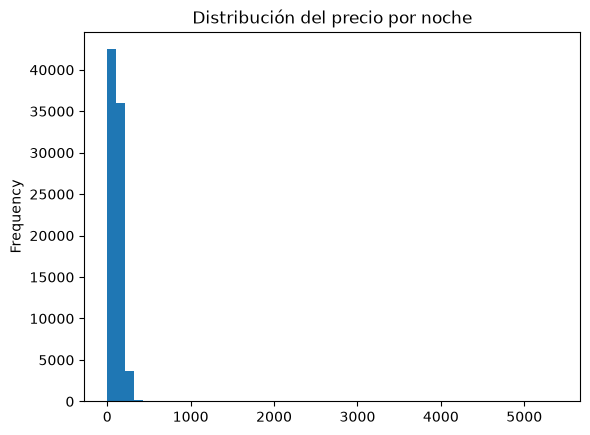

In [89]:
hoteles["precio_noche"].plot(kind="hist", bins=50, title="Distribución del precio por noche") # histograma del precio por noche

<Axes: title={'center': 'Distribución del precio por noche'}, ylabel='Frequency'>

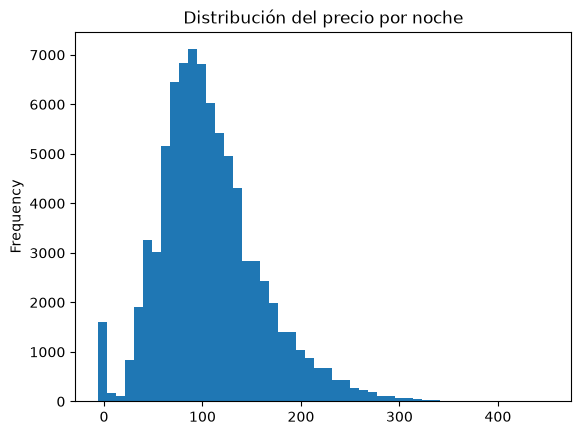

In [90]:
hoteles[hoteles["precio_noche"] < 500]["precio_noche"].plot(kind="hist", bins=50, title="Distribución del precio por noche") # histograma del precio por noche

<Axes: title={'center': 'Distribución de la antelación de la reserva'}, ylabel='Frequency'>

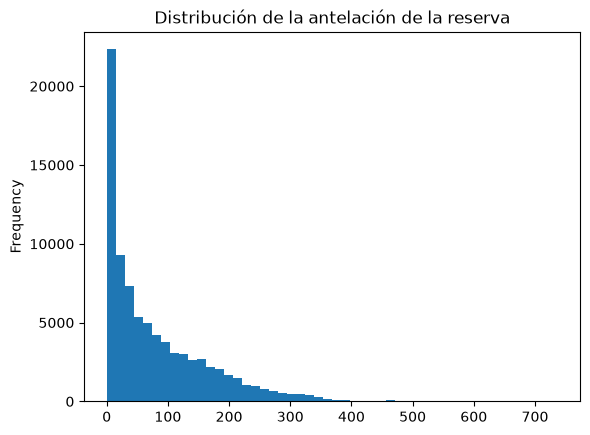

In [91]:
hoteles["antelacion"].plot(kind="hist", bins=50, title="Distribución de la antelación de la reserva") # histograma de la antelación de la reserva

### Ejercicios

**4.1** Haz el describe de pisos. ¿Qué te llama la atención del precio máximo?

In [92]:
pisos.describe() # estadísticos de las columnas numéricas

,id,latitud,longitud,precio,noches_minimas,reseñas,reseñas_mes,pisos_anfitrion,dias_libres
count,1.878500e+04,18785.000000,18785.000000,18785.000000,18785.000000,18785.000000,18785.000000,18785.000000,18785.000000
mean,9.828058e+17,40.423026,-3.693070,208.680756,7.097418,74.077988,2.018688,49.284110,187.222305
std,6.115261e+17,0.023854,0.028101,543.629872,15.471473,117.824652,2.574821,108.149167,128.975419
min,2.185300e+04,40.332270,-3.829970,9.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,6.228984e+17,40.410300,-3.707200,95.000000,1.000000,3.000000,0.290000,2.000000,60.000000
50%,1.151975e+18,40.420930,-3.700690,151.000000,2.000000,32.000000,1.280000,6.000000,219.000000
75%,1.487768e+18,40.433600,-3.683437,225.000000,3.000000,95.000000,3.000000,30.000000,312.000000
max,1.776242e+18,40.535530,-3.543030,36883.000000,365.000000,1600.000000,94.490000,469.000000,365.000000


**4.2** Saca la media y la mediana del precio. ¿Por qué crees que son tan distintas?

Resultado esperado: 208.7 y 151.0

In [93]:
print("Precio medio:", round(pisos["precio"].mean(), 1))
print("Precio mediano:", round(pisos["precio"].median(), 1))

Precio medio: 208.7
Precio mediano: 151.0


**4.3** Dibuja el histograma del precio.

<Axes: ylabel='Frequency'>

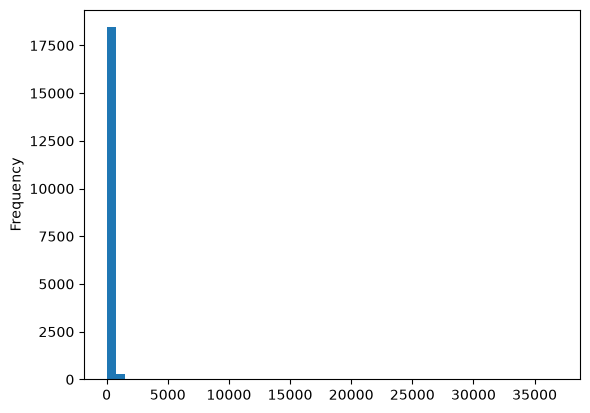

In [94]:
pisos["precio"].plot(kind="hist", bins=50)

**4.4** Ahora el histograma solo de los pisos de menos de 1000 euros.

<Axes: ylabel='Frequency'>

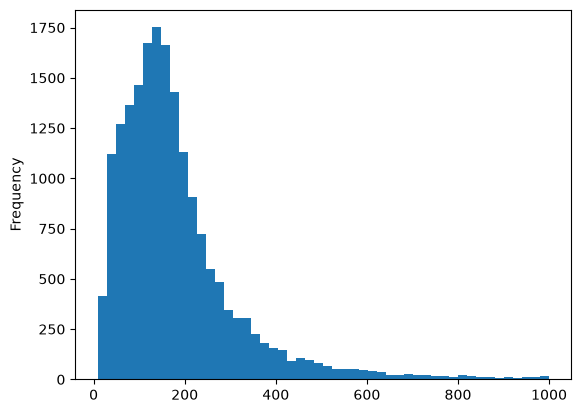

In [95]:
pisos[pisos["precio"] < 1000]["precio"].plot(kind="hist", bins=50)

**4.5** Dibuja el histograma de las noches mínimas. ¿Cuántas noches piden casi todos?

<Axes: ylabel='Frequency'>

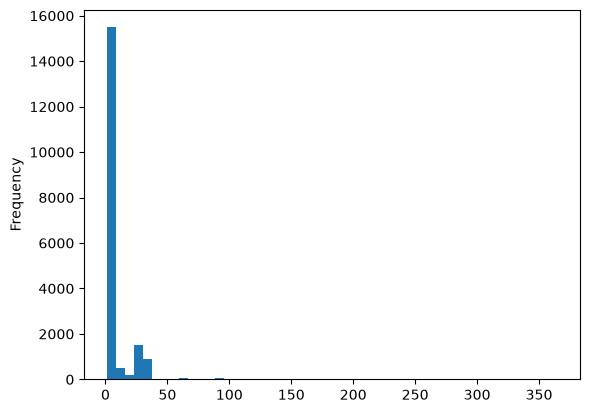

In [96]:
pisos["noches_minimas"].plot(kind="hist", bins=50)

## 5. Los valores raros

Buscamos valores imposibles o exagerados y vemos si son errores o casos reales.

In [97]:
hoteles.sort_values("precio_noche", ascending=False).head(10) # mostramos los 10 hoteles más caros

,hotel,cancelada,antelacion,año,mes,noches_finde,noches_semana,adultos,ninos,bebes,comida,pais,deposito,agente,precio_noche
48515,City Hotel,1,35,2016,March,0,1,2,0.0,0,BB,PRT,Non Refund,12.0,5400.00
111403,City Hotel,0,0,2017,May,0,1,1,0.0,0,BB,ITA,No Deposit,159.0,510.00
15083,Resort Hotel,0,1,2015,July,0,1,2,0.0,0,BB,PRT,No Deposit,0.0,508.00
103912,City Hotel,0,81,2016,December,1,1,2,2.0,0,BB,PRT,No Deposit,0.0,451.50
13142,Resort Hotel,1,378,2017,August,4,10,2,0.0,0,BB,PRT,No Deposit,314.0,450.00
13391,Resort Hotel,1,59,2017,August,2,4,2,2.0,0,FB,PRT,No Deposit,250.0,437.00
39155,Resort Hotel,0,31,2017,August,2,6,2,2.0,0,SC,PRT,No Deposit,250.0,426.25
39568,Resort Hotel,0,104,2017,August,2,3,3,1.0,0,HB,ESP,No Deposit,240.0,402.00
39118,Resort Hotel,0,26,2017,July,3,5,3,2.0,0,HB,MAR,No Deposit,250.0,397.38
39517,Resort Hotel,0,24,2017,August,0,3,2,0.0,0,HB,PRT,No Deposit,240.0,392.00


In [98]:
raros = hoteles[hoteles["precio_noche"] <= 0]
print("Precio 0 o negativo:", len(raros)) # mostramos el número de filas con precio 0 o negativo
raros.head() # mostramos las filas con precio 0 o negativo

Precio 0 o negativo: 1564


,hotel,cancelada,antelacion,año,mes,noches_finde,noches_semana,adultos,ninos,bebes,comida,pais,deposito,agente,precio_noche
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,0.0,0.0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,0.0,0.0
125,Resort Hotel,0,32,2015,July,0,1,4,0.0,0,FB,PRT,No Deposit,0.0,0.0
167,Resort Hotel,0,111,2015,July,0,0,2,0.0,0,BB,PRT,No Deposit,240.0,0.0
168,Resort Hotel,0,0,2015,July,0,0,1,0.0,0,BB,PRT,No Deposit,250.0,0.0


In [99]:
print("Reservas sin adultos:", len(hoteles[hoteles["adultos"] == 0])) # mostramos el número de filas con 0 adultos
hoteles[hoteles["bebes"] > 3]

Reservas sin adultos: 363


,hotel,cancelada,antelacion,año,mes,noches_finde,noches_semana,adultos,ninos,bebes,comida,pais,deposito,agente,precio_noche
46619,City Hotel,0,37,2016,January,0,2,2,0.0,10,BB,PRT,No Deposit,9.0,84.45
78656,City Hotel,0,11,2015,October,2,1,1,0.0,9,BB,GBR,No Deposit,95.0,95.00


<Axes: title={'center': 'Distribución del precio por noche'}>

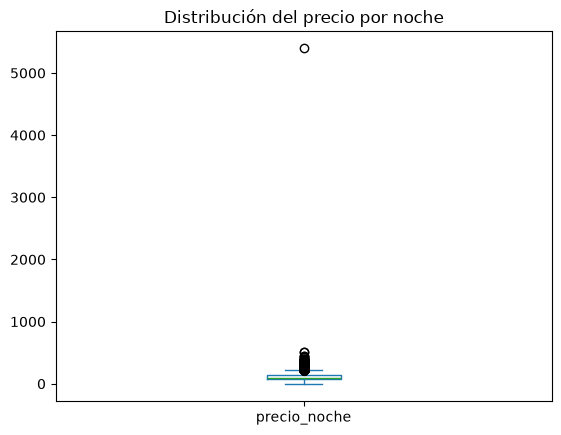

In [100]:
hoteles["precio_noche"].plot(kind="box", title="Distribución del precio por noche") # diagrama de caja del precio por noche

In [101]:
hoteles = hoteles[(hoteles["precio_noche"] > 0) & (hoteles["precio_noche"] < 1000)] # eliminamos las filas con precio 0 o negativo y las filas con precio mayor a 1000  
print(hoteles.shape) # filas y columnas
print("Precio medio:", round(hoteles["precio_noche"].mean(), 1), "€") # precio medio por noche
print("Precio mediana:", round(hoteles["precio_noche"].median(), 1), "€") # precio mediana por noche

(80668, 15)
Precio medio: 110.2 €
Precio mediana: 100.5 €


### Ejercicios

**5.1** Enseña los 10 pisos más caros.

In [102]:
pisos.sort_values("precio", ascending=False).head(10) # mostramos los 10 pisos más caros

,id,distrito,barrio,latitud,longitud,tipo,precio,noches_minimas,reseñas,reseñas_mes,pisos_anfitrion,dias_libres,licencia
6148,53056104,Centro,Universidad,40.42326,-3.71051,Entire home/apt,36883.0,5.0,2,0.03,11,351,Sin licencia
18084,1496308350558748700,Centro,Palacio,40.41596,-3.71117,Private room,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...
18089,1496323497168656654,Centro,Embajadores,40.40905,-3.69837,Private room,15000.0,1.0,0,0.00,10,364,Spain - National registration number<br />ESHF...
18081,1496255451562926135,Centro,Cortes,40.41461,-3.70288,Entire home/apt,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESFC...
18086,1496311962864630674,Centro,Palacio,40.41604,-3.71140,Private room,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...
18083,1496302830029735943,Centro,Cortes,40.41441,-3.70140,Private room,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...
18082,1496264019813624356,Centro,Cortes,40.41427,-3.70057,Entire home/apt,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...
18102,1498654933003051613,Centro,Embajadores,40.41103,-3.69894,Entire home/apt,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...
18075,1495756143572407893,Centro,Universidad,40.42371,-3.70279,Private room,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...
18101,1498653316318644494,Centro,Embajadores,40.41048,-3.69837,Entire home/apt,15000.0,1.0,0,0.00,10,365,Spain - National registration number<br />ESHF...


**5.2** ¿Cuántos pisos pasan de 1000 euros la noche? ¿Y de 5000?

Resultado esperado: 164 y 28

In [103]:
print("Mas de 1000€:", len(pisos[pisos["precio"] > 1000])) # mostramos el número de filas con precio mayor a 1000
print("Mas de 5000€:", len(pisos[pisos["precio"] > 5000])) # mostramos el número de filas con precio mayor a 5000

Mas de 1000€: 164
Mas de 5000€: 28


**5.3** Enseña los de más de 5000 euros. ¿Te parecen precios de verdad o errores?

In [104]:
pisos[pisos["precio"] > 5000].head() # mostramos las filas con precio mayor a 5000

,id,distrito,barrio,latitud,longitud,tipo,precio,noches_minimas,reseñas,reseñas_mes,pisos_anfitrion,dias_libres,licencia
3037,28299366,Latina,Aluche,40.392208,-3.760551,Private room,11980.0,3.0,0,0.00,1,270,Sin licencia
5021,43828290,Centro,Palacio,40.421700,-3.710090,Entire home/apt,9286.0,4.0,4,0.06,11,346,Madrid - Regional registration number<br />Exe...
5025,43842071,Centro,Palacio,40.420250,-3.710560,Entire home/apt,9344.0,4.0,0,0.00,11,351,Sin licencia
5082,44174305,Centro,Universidad,40.424217,-3.710314,Entire home/apt,9265.0,5.0,8,0.12,11,1,Sin licencia
5091,44261614,Centro,Palacio,40.419640,-3.710120,Entire home/apt,7964.0,30.0,0,0.00,11,330,Sin licencia


**5.4** Haz el diagrama de caja del precio.

<Axes: title={'center': 'Distribución del precio'}>

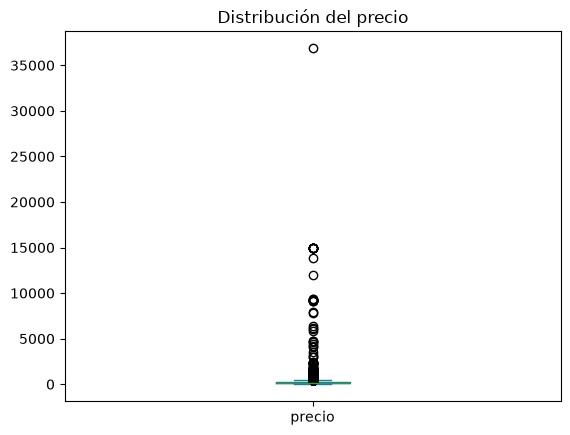

In [105]:
pisos["precio"].plot(kind="box", title="Distribución del precio") # diagrama de caja del precio

**5.5** Quédate solo con los pisos de menos de 1000 euros y vuelve a sacar la media y la mediana. ¿Se han acercado?

Resultado esperado: 180.7 y 150.0

In [106]:
pisos = pisos[pisos["precio"] < 1000] # eliminamos las filas con precio mayor a 1000
print(pisos.shape) # filas y columnas
print("Precio medio:", round(pisos["precio"].mean(), 1), "€") # precio medio por noche
print("Precio mediana:", round(pisos["precio"].median(), 1), "€") # precio mediana por noche

(18618, 13)
Precio medio: 180.7 €
Precio mediana: 150.0 €


## 6. Las categorías

Contamos cuántas filas hay de cada categoría.

### Ejercicios

**6.1** ¿Cuántos pisos hay de cada tipo? ¿Y en porcentaje?

Resultado esperado: 72.2 % pisos enteros

**6.2** Saca los 10 distritos con más pisos y dibújalos en barras.

**6.3** ¿Qué porcentaje de pisos no tiene licencia?

Resultado esperado: 42.0

**6.4** ¿Cuántos pisos son de anfitriones que tienen más de 50 pisos en Madrid?

Resultado esperado: 3698

## 7. Comparar grupos

Por ejemplo, si en un hotel se cancela más que en el otro, o si un distrito es más caro que otro.

### Ejercicios

**7.1** ¿Cuál es el precio mediano de cada distrito? Ordénalo de mayor a menor.

**7.2** ¿Y el precio mediano de cada tipo de alojamiento?

**7.3** ¿Cuántas noches mínimas piden de mediana según el tipo de alojamiento?

## 8. Relaciones entre columnas

Si cuando una columna sube la otra también sube (o baja), es que tienen relación.

### Ejercicios

**8.1** Haz un gráfico de puntos con la longitud abajo y la latitud a la izquierda, con s=1 para que los puntos sean pequeños. ¿Qué ciudad aparece?

**8.2** ¿Tienen relación las reseñas y el precio? Calcula su correlación.

Resultado esperado: 0.04

**8.3** Haz el gráfico de puntos de reseñas y precio. ¿Cuadra con la correlación?

## 9. Conclusiones

### Ejercicios

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos sobre los pisos turísticos de Madrid. Cada uno, en una frase con un número.

Escribe aquí tus tres hallazgos.

## Si acabas antes

Haz lo mismo con el CSV que guardaste ayer en el proyecto de la API. Crea un cuaderno nuevo en tu carpeta proyecto-api, carga tu CSV y repite los bloques del 1 al 9. Si no te acuerdas de cómo se hacía algo, búscalo en este cuaderno.